# E006 — Feature Group Combination & Ablation (CatBoost GPU)

**Project:** Bank Card Fraud Detection  
**Research question:** Can the most promising feature groups from E002–E005 work *together* to improve fraud ranking compared with the strongest single group?  
**Competition metric:** ROC AUC (higher is better).  
**Hardware:** NVIDIA GPU (`task_type="GPU", devices="0"`).

### What we already know (3-fold expanding-window CV)

| Earlier experiment | Main feature group | Mean CV ROC AUC |
|:--|:--|--:|
| E001 | Original 14 features | 0.87424 |
| E002-B | Customer spending | 0.89328 |
| **E003-A** | **Time since previous transaction** | **0.90917** |
| E004-C | Card–merchant familiarity | 0.88374 |
| E005-C | Geographic country changes | 0.89657 |

**Important:** We are **not** adding all features generated in E002–E005. We are combining only the **winning configuration from each experiment**. This produces **14 original + 4 spending + 1 velocity + 2 familiarity + 4 geographic = 25 features**.

### Experimental rules

1. Keep **identical three chronological folds** and CatBoost hyperparameters from E001–E005.
2. Recompute all chosen features using their **original formulas**, not new approximations.
3. Use **fraud labels only** for fitting models and calculating evaluation metrics. Card statistics across `train + test` use **unlabeled** fields, as explicitly permitted by the competition. These full-history aggregates are **transductive**, so this evaluation does *not* simulate strict real-time deployment.
4. Evaluate **forward group addition** and **backward group ablation** (removing groups from the full model).
5. Report **paired fold-level changes**, not just the highest mean AUC.

**Model-selection caveat:** We have inspected these same folds in many earlier experiments. These are useful development scores but are **not an independent final generalization estimate**. We will need a final independent evaluation strategy before claiming leaderboard performance.

## 1 — Imports and load the original transactions

`pd.read_csv()` loads the data. We parse train and test timestamps explicitly because the two files use different formats. `Path.cwd()` lets the same notebook run when opened from either the project root or its `notebooks/` folder.

Only `train.csv` contains `is_fraud`; `test.csv` supplies unlabeled feature values.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

working_dir = Path.cwd()
possible_data_dirs = [working_dir / "data", working_dir.parent / "data"]
data_dir = next(
    (folder for folder in possible_data_dirs
     if (folder / "train.csv").exists() and (folder / "test.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Place train.csv and test.csv in Fraud-Detection-CatBoost/data/"
    )
project_root = data_dir.parent
train_raw = pd.read_csv(data_dir / "train.csv")
test_raw = pd.read_csv(data_dir / "test.csv")

train_raw["timestamp"] = pd.to_datetime(
    train_raw["timestamp"], format="%Y-%m-%d %H:%M:%S"
)
test_raw["timestamp"] = pd.to_datetime(
    test_raw["timestamp"], format="%m/%d/%Y %H:%M"
)
train_raw = train_raw.sort_values("timestamp", kind="stable").reset_index(drop=True)

assert "is_fraud" in train_raw.columns and "is_fraud" not in test_raw.columns
assert train_raw["transaction_id"].is_unique and test_raw["transaction_id"].is_unique
assert train_raw["timestamp"].max() < test_raw["timestamp"].min()
assert train_raw["timestamp"].notna().all() and test_raw["timestamp"].notna().all()

print("Project:", project_root)
print(f"Train: {len(train_raw):,} rows, frauds: {int(train_raw['is_fraud'].sum()):,}")
print(f"Test : {len(test_raw):,} rows")
print("Train range:", train_raw["timestamp"].min(), "to", train_raw["timestamp"].max())
print("Test range: ", test_raw["timestamp"].min(), "to", test_raw["timestamp"].max())

Project: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost
Train: 60,197 rows, frauds: 799
Test : 39,803 rows
Train range: 2026-01-01 00:07:15 to 2026-02-05 23:59:19
Test range:  2026-02-06 00:07:00 to 2026-03-02 00:36:00


## 2 — Define the four selected feature groups

We intentionally use the **same formulas as the earlier notebooks**:

| Group | Original experiment | Features | Count |
|:--|:--|:--|--:|
| **Spending (S)** | E002-B | `card_amount_median`, `card_amount_mean`, `amount_to_card_median`, `amount_minus_card_median` | 4 |
| **Velocity (V)** | E003-A | `minutes_since_previous_txn` | 1 |
| **Familiarity (F)** | E004-C | `card_merchant_txn_count`, `card_unique_merchants` | 2 |
| **Geography (G)** | E005-C | `ip_country_changed_from_previous`, `merchant_country_changed_from_previous`, `ip_country_change_within_1h`, `merchant_country_change_within_1h` | 4 |

**Two types of information:**

- **Full-history aggregates:** S and F use the complete unlabeled `train + test` transaction table. This is permitted for this particular competition, but **not** strict causal real-time validation.
- **Past-only sequence features:** V and G consider only strictly earlier timestamps for each card. Tied timestamps do not count as previous transactions.

We'll build the complete set of 11 engineered columns once, then use a **feature registry** to select which columns each CatBoost model receives.

### 2A — Spending features (same as E002-B)

`groupby("card_id").agg(...)` computes each card's typical spending. `join(..., on="card_id")` maps its card-level values back to every transaction. No fraud labels enter this computation.

In [2]:
SPENDING_FEATURES = [
    "card_amount_median", "card_amount_mean",
    "amount_to_card_median", "amount_minus_card_median",
]

def build_spending_features(all_rows: pd.DataFrame) -> pd.DataFrame:
    # Compute from unlabeled transaction fields, matching E002-B.
    card_stats = (
        all_rows.groupby("card_id")["amount"]
        .agg(
            card_amount_median="median",
            card_amount_mean="mean",
            card_amount_std="std",              # computed as in E002
            card_transaction_count="size",      # not selected in E006
        )
    )
    card_stats["card_amount_std"] = card_stats["card_amount_std"].fillna(0.0)
    output = all_rows[["transaction_id", "card_id", "amount"]].join(
        card_stats, on="card_id"
    )
    typical_amount = output["card_amount_median"].clip(lower=1e-6)
    output["amount_to_card_median"] = output["amount"] / typical_amount
    output["amount_minus_card_median"] = (
        output["amount"] - output["card_amount_median"]
    )
    return output[["transaction_id"] + SPENDING_FEATURES].copy()

### 2B — Transaction velocity (same as E003-A)

For each card, `minutes_since_previous_txn` is the gap to the preceding **distinct** timestamp. If no earlier transaction exists, it equals **−1**, matching E003. The function below is reused from E003's validated feature builder (it also computes other velocity columns, but E006 selects only the winning time-gap feature).

In [3]:
VELOCITY_FEATURES = [
    "minutes_since_previous_txn",
    "card_txn_5min",
    "card_txn_1h",
    "card_txn_24h",
    "card_amount_sum_1h",
]


def build_velocity_features(transaction_rows: pd.DataFrame) -> pd.DataFrame:
    """Return one transaction_id + past-only velocity features per input row.

    Required columns: transaction_id, card_id, timestamp (datetime64), amount.
    Never reads is_fraud or any future transaction for a feature at time t.
    """
    required = ["transaction_id", "card_id", "timestamp", "amount"]
    if not set(required).issubset(transaction_rows.columns):
        raise ValueError(f"Missing columns from {required}")

    events = transaction_rows[required].copy()
    if not events["transaction_id"].is_unique:
        raise ValueError("transaction_id must be unique")
    if events["timestamp"].isna().any() or events["card_id"].isna().any():
        raise ValueError("card_id and timestamp must not be missing")
    if events["amount"].isna().any():
        raise ValueError("amount must not be missing")

    # Stable sorting makes events for the same card chronological.
    events = events.sort_values(["card_id", "timestamp"], kind="stable").reset_index(drop=True)
    row_count = len(events)

    gap_minutes = np.full(row_count, -1.0, dtype=np.float64)
    count_5min = np.zeros(row_count, dtype=np.int32)
    count_1h = np.zeros(row_count, dtype=np.int32)
    count_24h = np.zeros(row_count, dtype=np.int32)
    amount_sum_1h = np.zeros(row_count, dtype=np.float64)

    minute_ns = 60 * 1_000_000_000
    hour_ns = 60 * minute_ns
    day_ns = 24 * hour_ns

    # Each group contains exactly one card. The indices are positions in events.
    for card_id, positions in events.groupby("card_id", sort=False).indices.items():
        card_rows = events.iloc[positions]
        times_ns = card_rows["timestamp"].to_numpy(dtype="datetime64[ns]").astype("int64")
        amounts = card_rows["amount"].to_numpy(dtype=np.float64)

        # Index of first event at current time; excludes current and tied events.
        prior_end = np.searchsorted(times_ns, times_ns, side="left")
        has_prior = prior_end > 0

        local_gaps = np.full(len(times_ns), -1.0, dtype=np.float64)
        previous_positions = prior_end[has_prior] - 1
        local_gaps[has_prior] = (
            times_ns[has_prior] - times_ns[previous_positions]
        ) / minute_ns
        gap_minutes[positions] = local_gaps

        window_5min = np.searchsorted(times_ns, times_ns - 5 * minute_ns, side="left")
        window_1h = np.searchsorted(times_ns, times_ns - hour_ns, side="left")
        window_24h = np.searchsorted(times_ns, times_ns - day_ns, side="left")

        count_5min[positions] = prior_end - window_5min
        count_1h[positions] = prior_end - window_1h
        count_24h[positions] = prior_end - window_24h

        # Prefix sums allow O(1) calculation of spending in any time window.
        cumulative_amount = np.r_[0.0, np.cumsum(amounts)]
        amount_sum_1h[positions] = (
            cumulative_amount[prior_end] - cumulative_amount[window_1h]
        )

    events["minutes_since_previous_txn"] = gap_minutes
    events["card_txn_5min"] = count_5min
    events["card_txn_1h"] = count_1h
    events["card_txn_24h"] = count_24h
    events["card_amount_sum_1h"] = np.maximum(amount_sum_1h, 0.0)

    # Restore input transaction order using a one-to-one key.
    return transaction_rows[["transaction_id"]].merge(
        events[["transaction_id"] + VELOCITY_FEATURES],
        on="transaction_id", how="left", validate="one_to_one", sort=False
    )

### 2C — Card–merchant familiarity (same as E004-C)

`card_merchant_txn_count` measures how often a card–merchant pair occurs across the **complete unlabeled** data, including the current transaction. `card_unique_merchants` counts distinct merchants per card. These features are not prior-only visits; we retain E004's formula to keep experiments comparable.

The original E004 builder also calculates device and other merchant fields, which are **not selected** in E006.

In [4]:
DEVICE_FEATURES = [
    "device_txn_count",
    "device_unique_cards",
    "card_unique_devices",
    "card_device_txn_count",
]
MERCHANT_FEATURES = [
    "merchant_txn_count",
    "merchant_unique_cards",
    "merchant_amount_median",
]
FAMILIARITY_FEATURES = [
    "card_merchant_txn_count",
    "card_unique_merchants",
]
ENGINEERED_FEATURES = DEVICE_FEATURES + MERCHANT_FEATURES + FAMILIARITY_FEATURES


def build_device_merchant_features(transaction_rows: pd.DataFrame) -> pd.DataFrame:
    """Return transaction_id + label-free device/merchant aggregate features.

    Only uses: transaction_id, card_id, device_id, merchant_id, amount.
    Group statistics include all supplied unlabeled rows, including the current row.
    """
    required_columns = [
        "transaction_id", "card_id", "device_id", "merchant_id", "amount"
    ]
    if not set(required_columns).issubset(transaction_rows.columns):
        raise ValueError(f"Missing required fields: {set(required_columns) - set(transaction_rows.columns)}")

    events = transaction_rows[required_columns].copy()
    if not events["transaction_id"].is_unique:
        raise ValueError("transaction_id must be unique for one-to-one joining")
    if events[["card_id", "merchant_id", "amount"]].isna().any().any():
        raise ValueError("card_id, merchant_id, and amount must not be missing")

    # Blank device IDs mean "no device", not a common device shared by all rows.
    has_real_device = events["device_id"].fillna("").astype(str).str.strip().ne("")
    online_devices = events.loc[has_real_device, ["card_id", "device_id"]].copy()

    device_stats = (
        online_devices.groupby("device_id", as_index=False)
        .agg(device_txn_count=("card_id", "size"),
             device_unique_cards=("card_id", "nunique"))
    )
    card_device_diversity = (
        online_devices.groupby("card_id", as_index=False)
        .agg(card_unique_devices=("device_id", "nunique"))
    )
    card_device_frequency = (
        online_devices.groupby(["card_id", "device_id"], as_index=False)
        .size().rename(columns={"size": "card_device_txn_count"})
    )

    merchant_stats = (
        events.groupby("merchant_id", as_index=False)
        .agg(merchant_txn_count=("transaction_id", "size"),
             merchant_unique_cards=("card_id", "nunique"),
             merchant_amount_median=("amount", "median"))
    )
    card_merchant_frequency = (
        events.groupby(["card_id", "merchant_id"], as_index=False)
        .size().rename(columns={"size": "card_merchant_txn_count"})
    )
    card_merchant_diversity = (
        events.groupby("card_id", as_index=False)
        .agg(card_unique_merchants=("merchant_id", "nunique"))
    )

    features = events[["transaction_id", "card_id", "merchant_id", "device_id"]].copy()
    features = features.merge(device_stats, on="device_id", how="left", validate="many_to_one", sort=False)
    features = features.merge(card_device_diversity, on="card_id", how="left", validate="many_to_one", sort=False)
    features = features.merge(
        card_device_frequency, on=["card_id", "device_id"],
        how="left", validate="many_to_one", sort=False
    )
    features = features.merge(merchant_stats, on="merchant_id", how="left", validate="many_to_one", sort=False)
    features = features.merge(
        card_merchant_frequency, on=["card_id", "merchant_id"],
        how="left", validate="many_to_one", sort=False
    )
    features = features.merge(
        card_merchant_diversity, on="card_id", how="left", validate="many_to_one", sort=False
    )

    # The first three device-specific counts are 0 if this transaction has no real device;
    # card_unique_devices is 0 only for a card that has never used a real device.
    for feature in ["device_txn_count", "device_unique_cards",
                    "card_unique_devices", "card_device_txn_count"]:
        features[feature] = features[feature].fillna(0).astype("int32")
    for feature in ["merchant_txn_count", "merchant_unique_cards",
                    "card_merchant_txn_count", "card_unique_merchants"]:
        features[feature] = features[feature].astype("int32")

    assert len(features) == len(events)
    assert features["transaction_id"].equals(events["transaction_id"])
    assert features[ENGINEERED_FEATURES].notna().all().all()
    return features[["transaction_id"] + ENGINEERED_FEATURES]

### 2D — Country-change features (same as E005-C)

For a given card, compare the current country with that from its preceding **distinct** transaction timestamp. If several transactions share one timestamp, the function handles their predecessor as a group; if the previous group contains conflicting countries, it uses **−1 (unknown)** rather than inventing a previous country.

The E005 function also computes country-familiarity and relationship fields, which are **not selected** in E006.

In [5]:
RELATIONSHIP_FEATURES = [
    "ip_merchant_country_mismatch",
    "geo_country_pattern",
]
FAMILIARITY_FEATURES = [
    "card_unique_ip_countries",
    "card_unique_merchant_countries",
    "card_ip_country_txn_count",
    "card_merchant_country_txn_count",
    "card_ip_country_share",
    "card_merchant_country_share",
]
SWITCH_FEATURES = [
    "ip_country_changed_from_previous",
    "merchant_country_changed_from_previous",
    "ip_country_change_within_1h",
    "merchant_country_change_within_1h",
]
ALL_GEO_FEATURES = RELATIONSHIP_FEATURES + FAMILIARITY_FEATURES + SWITCH_FEATURES
GEO_CATEGORICAL_FEATURES = ["geo_country_pattern"]


def build_geographic_features(transaction_rows: pd.DataFrame) -> pd.DataFrame:
    """Create label-free geographic features, one row per transaction.

    Full-history card-country statistics use only the supplied unlabeled fields.
    Country-change flags compare each transaction only with the preceding
    DISTINCT timestamp of the same card; simultaneous events are never past.

    Returns: DataFrame with transaction_id and ALL_GEO_FEATURES.
    """
    needed = [
        "transaction_id", "timestamp", "card_id", "customer_home_country",
        "merchant_country", "ip_country",
    ]
    missing = set(needed) - set(transaction_rows.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    events = transaction_rows[needed].copy()
    if not events["transaction_id"].is_unique:
        raise ValueError("transaction_id must be unique")
    if events[needed].isna().any().any():
        raise ValueError("No missing values are expected in required geographic fields")
    if not pd.api.types.is_datetime64_any_dtype(events["timestamp"]):
        raise TypeError("timestamp must be parsed as pandas datetime before engineering")

    # A: relationships among home, merchant, and IP countries.
    ip_foreign = events["ip_country"] != events["customer_home_country"]
    merchant_foreign = events["merchant_country"] != events["customer_home_country"]
    ip_merchant_equal = events["ip_country"] == events["merchant_country"]

    features = events[["transaction_id", "card_id", "timestamp",
                       "ip_country", "merchant_country"]].copy()
    features["ip_merchant_country_mismatch"] = (~ip_merchant_equal).astype("int8")
    features["geo_country_pattern"] = np.select(
        [
            ~ip_foreign & ~merchant_foreign,
            ip_foreign & ~merchant_foreign,
            ~ip_foreign & merchant_foreign,
            ip_foreign & merchant_foreign & ip_merchant_equal,
            ip_foreign & merchant_foreign & ~ip_merchant_equal,
        ],
        [
            "all_local", "ip_only_foreign", "merchant_only_foreign",
            "both_foreign_same", "both_foreign_different",
        ],
        default="unknown",
    )
    assert not (features["geo_country_pattern"] == "unknown").any()

    # B: full-history unlabeled card-country familiarity and diversity.
    card_stats = (
        events.groupby("card_id", as_index=False)
        .agg(
            card_transaction_count=("transaction_id", "size"),
            card_unique_ip_countries=("ip_country", "nunique"),
            card_unique_merchant_countries=("merchant_country", "nunique"),
        )
    )
    card_ip_counts = (
        events.groupby(["card_id", "ip_country"], as_index=False)
        .size().rename(columns={"size": "card_ip_country_txn_count"})
    )
    card_merchant_counts = (
        events.groupby(["card_id", "merchant_country"], as_index=False)
        .size().rename(columns={"size": "card_merchant_country_txn_count"})
    )
    features = features.merge(card_stats, on="card_id", how="left",
                              validate="many_to_one", sort=False)
    features = features.merge(card_ip_counts, on=["card_id", "ip_country"],
                              how="left", validate="many_to_one", sort=False)
    features = features.merge(card_merchant_counts,
                              on=["card_id", "merchant_country"],
                              how="left", validate="many_to_one", sort=False)
    features["card_ip_country_share"] = (
        features["card_ip_country_txn_count"] / features["card_transaction_count"]
    )
    features["card_merchant_country_share"] = (
        features["card_merchant_country_txn_count"] / features["card_transaction_count"]
    )

    # C: one representative country per (card_id, timestamp), ONLY if unambiguous.
    # Previous-timestamp state is shifted at the timestamp-group level first.
    # Every transaction at one timestamp gets the SAME previous timestamp/state.
    time_state = (
        events.groupby(["card_id", "timestamp"], as_index=False, sort=True)
        .agg(
            time_ip_country=("ip_country", "first"),
            time_merchant_country=("merchant_country", "first"),
            time_ip_nunique=("ip_country", "nunique"),
            time_merchant_nunique=("merchant_country", "nunique"),
        )
    )
    for current_column, shifted_column in [
        ("timestamp", "prior_timestamp"),
        ("time_ip_country", "prior_ip_country"),
        ("time_merchant_country", "prior_merchant_country"),
        ("time_ip_nunique", "prior_ip_nunique"),
        ("time_merchant_nunique", "prior_merchant_nunique"),
    ]:
        time_state[shifted_column] = (
            time_state.groupby("card_id", sort=False)[current_column].shift(1)
        )
    previous_columns = [
        "card_id", "timestamp", "prior_timestamp", "prior_ip_country",
        "prior_merchant_country", "prior_ip_nunique", "prior_merchant_nunique",
    ]
    features = features.merge(
        time_state[previous_columns], on=["card_id", "timestamp"],
        how="left", validate="many_to_one", sort=False,
    )
    gap_minutes = (
        (features["timestamp"] - features["prior_timestamp"]).dt.total_seconds() / 60
    )
    assert (gap_minutes.dropna() > 0).all(), "Previous timestamp must be strictly earlier"

    known_ip_previous = features["prior_ip_nunique"].eq(1)
    known_merchant_previous = features["prior_merchant_nunique"].eq(1)
    ip_changed = features["ip_country"].ne(features["prior_ip_country"])
    merchant_changed = features["merchant_country"].ne(features["prior_merchant_country"])
    in_one_hour = gap_minutes.le(60)

    features["ip_country_changed_from_previous"] = np.where(
        known_ip_previous, ip_changed.astype("int8"), -1
    ).astype("int8")
    features["merchant_country_changed_from_previous"] = np.where(
        known_merchant_previous, merchant_changed.astype("int8"), -1
    ).astype("int8")
    features["ip_country_change_within_1h"] = np.where(
        known_ip_previous, (ip_changed & in_one_hour).astype("int8"), -1
    ).astype("int8")
    features["merchant_country_change_within_1h"] = np.where(
        known_merchant_previous, (merchant_changed & in_one_hour).astype("int8"), -1
    ).astype("int8")

    result = features[["transaction_id"] + ALL_GEO_FEATURES].copy()
    assert len(result) == len(events)
    assert np.array_equal(result["transaction_id"].to_numpy(), events["transaction_id"].to_numpy())
    assert result[ALL_GEO_FEATURES].notna().all().all()
    return result

## 3 — Build one reproducible feature table

Concatenate only **unlabeled** transaction columns, calculate each feature group, then merge back by the unique `transaction_id`. We verify that row counts, original row order, and non-missing engineered values are preserved.

In [6]:
# Include ONLY the input columns required by our feature functions.
input_columns = [
    "transaction_id", "timestamp", "card_id", "amount", "device_id",
    "merchant_id", "customer_home_country", "merchant_country", "ip_country",
]
all_unlabeled = pd.concat(
    [train_raw[input_columns], test_raw[input_columns]],
    ignore_index=True,
)
assert all_unlabeled["transaction_id"].is_unique
assert "is_fraud" not in all_unlabeled.columns

spending_table = build_spending_features(
    all_unlabeled[["transaction_id", "card_id", "amount"]]
)
velocity_table = build_velocity_features(
    all_unlabeled[["transaction_id", "card_id", "timestamp", "amount"]]
)[["transaction_id", "minutes_since_previous_txn"]]
merchant_table = build_device_merchant_features(
    all_unlabeled[["transaction_id", "card_id", "device_id", "merchant_id", "amount"]]
)[["transaction_id", "card_merchant_txn_count", "card_unique_merchants"]]
geo_table = build_geographic_features(
    all_unlabeled[["transaction_id", "timestamp", "card_id", "customer_home_country",
                   "merchant_country", "ip_country"]]
)[["transaction_id"] + [
    "ip_country_changed_from_previous",
    "merchant_country_changed_from_previous",
    "ip_country_change_within_1h",
    "merchant_country_change_within_1h",
]]

all_engineered_tables = [spending_table, velocity_table, merchant_table, geo_table]
engineered_table = all_unlabeled[["transaction_id"]].copy()
for table in all_engineered_tables:
    assert len(table) == len(all_unlabeled)
    assert table["transaction_id"].is_unique
    engineered_table = engineered_table.merge(
        table, on="transaction_id", how="left",
        validate="one_to_one", sort=False,
    )

train_features = train_raw.merge(
    engineered_table, on="transaction_id", how="left",
    validate="one_to_one", sort=False,
)
test_features = test_raw.merge(
    engineered_table, on="transaction_id", how="left",
    validate="one_to_one", sort=False,
)

SELECTED_FEATURES = (
    SPENDING_FEATURES
    + ["minutes_since_previous_txn"]
    + ["card_merchant_txn_count", "card_unique_merchants"]
    + ["ip_country_changed_from_previous", "merchant_country_changed_from_previous",
       "ip_country_change_within_1h", "merchant_country_change_within_1h"]
)
assert len(SELECTED_FEATURES) == 11
assert len(train_features) == len(train_raw) and len(test_features) == len(test_raw)
assert train_features["transaction_id"].equals(train_raw["transaction_id"])
assert test_features["transaction_id"].equals(test_raw["transaction_id"])
assert train_features[SELECTED_FEATURES].notna().all().all()
assert test_features[SELECTED_FEATURES].notna().all().all()

print("Unlabeled rows used for engineering:", len(all_unlabeled))
print("Engineered columns selected for E006:", len(SELECTED_FEATURES))
print("Train + features shape:", train_features.shape)
display(train_features[["card_id", "amount", "merchant_id"] + SELECTED_FEATURES].head(8))

Unlabeled rows used for engineering: 100000
Engineered columns selected for E006: 11
Train + features shape: (60197, 31)


,card_id,amount,merchant_id,card_amount_median,card_amount_mean,amount_to_card_median,amount_minus_card_median,minutes_since_previous_txn,card_merchant_txn_count,card_unique_merchants,ip_country_changed_from_previous,merchant_country_changed_from_previous,ip_country_change_within_1h,merchant_country_change_within_1h
0,C03949,171.70,M00042,32.390,83.081951,5.301019,139.310,-1.0,4,21,-1,-1,-1,-1
1,C02996,248.09,M00532,32.070,44.750588,7.735890,216.020,-1.0,3,12,-1,-1,-1,-1
2,C06754,305.51,M00800,39.740,61.286429,7.687720,265.770,-1.0,1,12,-1,-1,-1,-1
3,C03321,7.47,M01947,19.490,26.765676,0.383273,-12.020,-1.0,5,24,-1,-1,-1,-1
4,C00958,18.58,M00380,9.540,9.540000,1.947589,9.040,-1.0,1,2,-1,-1,-1,-1
5,C00186,20.64,M01180,22.670,38.396667,0.910454,-2.030,-1.0,1,14,-1,-1,-1,-1
6,C00579,85.35,M00527,64.200,360.360526,1.329439,21.150,-1.0,1,30,-1,-1,-1,-1
7,C05199,15.95,M00038,13.335,15.370000,1.196100,2.615,-1.0,1,12,-1,-1,-1,-1


## 4 — Sanity checks before model training

These checks guard against three common mistakes:

1. **Accidental label leakage:** No target column enters the engineering functions.
2. **Bad joins:** Each transaction still appears exactly once.
3. **Incorrect sequence logic:** Future transactions cannot alter earlier **velocity or country-change** features, because both use strictly earlier timestamps. (The *full-history aggregates* deliberately do use future unlabeled rows by competition permission.)

We also test two numerical features against manual definitions for a sample card and confirm that missing time gaps are represented as −1.

In [7]:
assert "is_fraud" not in all_unlabeled.columns
assert train_features[SELECTED_FEATURES].select_dtypes(include="number").shape[1] == 11
assert (train_features["card_amount_median"] > 0).all()
assert (train_features["card_merchant_txn_count"] >= 1).all()
assert (train_features["card_unique_merchants"] >= 1).all()
assert (train_features["minutes_since_previous_txn"] >= -1).all()

# Manual spot check of a full-history card–merchant count.
spot = train_features.iloc[0]
expected_visits = int((
    (all_unlabeled["card_id"] == spot["card_id"])
    & (all_unlabeled["merchant_id"] == spot["merchant_id"])
).sum())
assert int(spot["card_merchant_txn_count"]) == expected_visits

# Manual spot check for a card's spending median.
expected_median = all_unlabeled.loc[
    all_unlabeled["card_id"].eq(spot["card_id"]), "amount"
].median()
assert np.isclose(float(spot["card_amount_median"]), expected_median)

# Future records must not modify earlier *past-only* feature values.
cutoff = pd.Timestamp("2026-01-19")
earlier = all_unlabeled.loc[all_unlabeled["timestamp"].lt(cutoff)]
early_ids = earlier["transaction_id"]
early_velocity = build_velocity_features(
    earlier[["transaction_id", "card_id", "timestamp", "amount"]]
)[["transaction_id", "minutes_since_previous_txn"]]
previous_velocity = velocity_table.loc[
    velocity_table["transaction_id"].isin(early_ids),
    ["transaction_id", "minutes_since_previous_txn"]
]
check = early_velocity.merge(
    previous_velocity, on="transaction_id", suffixes=("_early", "_all"),
    how="inner", validate="one_to_one"
)
assert len(check) == len(earlier)
assert np.allclose(
    check["minutes_since_previous_txn_early"],
    check["minutes_since_previous_txn_all"],
)

SWITCH_COLS = [
    "ip_country_changed_from_previous", "merchant_country_changed_from_previous",
    "ip_country_change_within_1h", "merchant_country_change_within_1h",
]
early_geo = build_geographic_features(
    earlier[["transaction_id", "timestamp", "card_id", "customer_home_country",
             "merchant_country", "ip_country"]]
)[["transaction_id"] + SWITCH_COLS]
geo_check = early_geo.merge(
    geo_table.loc[geo_table["transaction_id"].isin(early_ids)],
    on="transaction_id", how="inner", validate="one_to_one",
    suffixes=("_early", "_all"),
)
assert len(geo_check) == len(earlier)
for column in SWITCH_COLS:
    assert (geo_check[f"{column}_early"] == geo_check[f"{column}_all"]).all(), column

print("PASS: labels excluded, row integrity, manual aggregates, past-only checks.")

PASS: labels excluded, row integrity, manual aggregates, past-only checks.


## 5 — Feature group registry and experiment design

**Forward addition:** start from the strongest earlier standalone group (Velocity), then add Spending → Geography → Familiarity.

**Backward ablation:** start from the full combination (E006-D) and remove one group at a time. E006-C is exactly **Full − Familiarity**, so we reuse that result instead of training it again.

| ID | Feature groups | Number of features | Question |
|:--|:--|--:|:--|
| E001-repeat | Original only | 14 | Is our baseline reproducible? |
| E006-A | V | 15 | Reproduce the best standalone velocity model |
| E006-B | V + S | 19 | Does spending improve velocity? |
| E006-C | V + S + G | 23 | Does geography further help? |
| E006-D | V + S + G + F | **25** | Does familiarity help the full set? |
| E006-E_no_velocity | S + G + F | 24 | How valuable is velocity conditional on all other groups? |
| E006-E_no_spending | V + G + F | 21 | How valuable is spending conditional on all other groups? |
| E006-E_no_geography | V + S + F | 21 | How valuable is geography conditional on all other groups? |

**Total:** 8 configurations × 3 chronological folds = **24 CatBoost GPU fits**.  
`group_ablation_delta = AUC(full model) − AUC(full model without group)`.

A positive delta suggests the feature group provides additional value **conditional on the other groups**, for this particular three-fold validation design. Results for correlated groups may interact, so ablation effects need not sum to the overall gain.

In [8]:
excluded_columns = {
    "transaction_id", "timestamp", "card_holder", "merchant_name",
    "ip_address", "is_fraud",
}
original_features = [
    column for column in train_raw.columns if column not in excluded_columns
]
assert len(original_features) == 14, original_features

feature_groups = {
    "S": SPENDING_FEATURES,
    "V": ["minutes_since_previous_txn"],
    "F": ["card_merchant_txn_count", "card_unique_merchants"],
    "G": SWITCH_COLS,
}

def make_feature_set(*group_names):
    """Original 14 columns plus each requested engineered group, without duplicates."""
    columns = original_features.copy()
    for name in group_names:
        columns += feature_groups[name]
    assert len(columns) == len(set(columns)), "Duplicate feature name"
    assert set(columns).issubset(train_features.columns)
    return columns

feature_sets = {
    "E001-repeat": make_feature_set(),
    "E006-A": make_feature_set("V"),
    "E006-B": make_feature_set("V", "S"),
    "E006-C": make_feature_set("V", "S", "G"),
    "E006-D": make_feature_set("V", "S", "G", "F"),
    "E006-E_no_velocity": make_feature_set("S", "G", "F"),
    "E006-E_no_spending": make_feature_set("V", "G", "F"),
    "E006-E_no_geography": make_feature_set("V", "S", "F"),
}

original_cat_features = train_raw[original_features].select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
assert len(feature_sets["E006-D"]) == 25
assert len(original_cat_features) == 8, original_cat_features

time_folds = [
    ("2026-01-19", "2026-01-25"),
    ("2026-01-25", "2026-01-31"),
    ("2026-01-31", "2026-02-06"),
]

for experiment_id, columns in feature_sets.items():
    print(f"{experiment_id:23s}: {len(columns):2d} features")
print("Categorical features:", original_cat_features)

fold_overview = []
for fold, (start, end) in enumerate(time_folds, 1):
    start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
    tr = train_features["timestamp"].lt(start_date)
    va = train_features["timestamp"].ge(start_date) & train_features["timestamp"].lt(end_date)
    assert tr.any() and va.any()
    assert train_features.loc[tr, "timestamp"].max() < train_features.loc[va, "timestamp"].min()
    assert train_features.loc[tr, "is_fraud"].nunique() == 2
    assert train_features.loc[va, "is_fraud"].nunique() == 2
    fold_overview.append({
        "fold": fold, "train_end_exclusive": start, "valid_end_exclusive": end,
        "train_rows": int(tr.sum()), "valid_rows": int(va.sum()),
        "train_frauds": int(train_features.loc[tr, "is_fraud"].sum()),
        "valid_frauds": int(train_features.loc[va, "is_fraud"].sum()),
    })
display(pd.DataFrame(fold_overview))

E001-repeat            : 14 features
E006-A                 : 15 features
E006-B                 : 19 features
E006-C                 : 23 features
E006-D                 : 25 features
E006-E_no_velocity     : 24 features
E006-E_no_spending     : 21 features
E006-E_no_geography    : 21 features
Categorical features: ['card_id', 'customer_home_country', 'merchant_id', 'merchant_category', 'merchant_country', 'channel', 'device_id', 'ip_country']


,fold,train_end_exclusive,valid_end_exclusive,train_rows,valid_rows,train_frauds,valid_frauds
0,1,2026-01-19,2026-01-25,29618,10336,409,140
1,2,2026-01-25,2026-01-31,39954,10263,549,94
2,3,2026-01-31,2026-02-06,50217,9980,643,156


## 6 — Train E006 on your NVIDIA GPU (24 separate fits)

We keep the **exact E001–E005 CatBoost settings**:

`iterations=600`, `depth=6`, `learning_rate=0.05`, `l2_leaf_reg=3`, `loss_function="Logloss"`, `eval_metric="AUC"`, `random_seed=42`, `early_stopping_rounds=70`, `use_best_model=True`.

Every fold gets a **fresh** CatBoost model. For each configuration and fold:

1. Select the requested feature columns.
2. Convert `card_present` to integer and missing categoricals to `"__MISSING__"` (same as E001).
3. Train with **earlier dates** and evaluate on the subsequent validation dates.
4. Save fold AUC, best iteration, runtime, and feature importance.

**Important:** The code uses the GPU by default. It will **not silently fall back to CPU**. With 24 fits, expect more work than the previous single-group experiments. The AUC monitoring warning from CatBoost GPU is informational, not a failure.

In [9]:
EXPERIMENTS_TO_RUN = list(feature_sets.keys())

model_parameters = dict(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    task_type="GPU",  # GPU training, no silent CPU fallback
    devices="0",      # RTX 3070
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

results_records = []
importance_records = []

for experiment_id in EXPERIMENTS_TO_RUN:
    feature_columns = feature_sets[experiment_id]
    categorical_columns = [
        column for column in original_cat_features if column in feature_columns
    ]
    print(f"\n===== {experiment_id}: {len(feature_columns)} features =====", flush=True)

    for fold, (start, end) in enumerate(time_folds, 1):
        start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
        train_mask = train_features["timestamp"].lt(start_date)
        valid_mask = (
            train_features["timestamp"].ge(start_date)
            & train_features["timestamp"].lt(end_date)
        )
        X_train = train_features.loc[train_mask, feature_columns].copy()
        X_valid = train_features.loc[valid_mask, feature_columns].copy()
        y_train = train_features.loc[train_mask, "is_fraud"]
        y_valid = train_features.loc[valid_mask, "is_fraud"]

        for frame in (X_train, X_valid):
            frame["card_present"] = frame["card_present"].astype("int8")
            frame[categorical_columns] = (
                frame[categorical_columns].fillna("__MISSING__").astype(str)
            )

        assert X_train.columns.tolist() == X_valid.columns.tolist()
        assert X_train[categorical_columns].notna().all().all()
        assert X_valid[categorical_columns].notna().all().all()
        assert X_train.select_dtypes(include="number").notna().all().all()
        assert X_valid.select_dtypes(include="number").notna().all().all()
        assert "is_fraud" not in X_train.columns

        model = CatBoostClassifier(**model_parameters)
        start_clock = perf_counter()
        model.fit(
            X_train, y_train,
            cat_features=categorical_columns,
            eval_set=(X_valid, y_valid),
            early_stopping_rounds=70,
            use_best_model=True,
        )
        duration_seconds = perf_counter() - start_clock

        valid_probabilities = model.predict_proba(X_valid)[:, 1]
        valid_auc = roc_auc_score(y_valid, valid_probabilities)

        results_records.append({
            "experiment_id": experiment_id,
            "fold": fold,
            "feature_count": len(feature_columns),
            "train_rows": len(y_train),
            "valid_rows": len(y_valid),
            "valid_frauds": int(y_valid.sum()),
            "roc_auc": float(valid_auc),
            "best_iteration": int(model.best_iteration_),
            "training_seconds": round(duration_seconds, 2),
        })
        for feature_name, importance in zip(
            feature_columns, model.get_feature_importance()
        ):
            importance_records.append({
                "experiment_id": experiment_id,
                "fold": fold,
                "feature": feature_name,
                "importance": float(importance),
            })
        print(
            f"Fold {fold} | ROC AUC={valid_auc:.5f} | "
            f"best_iteration={model.best_iteration_} | "
            f"time={duration_seconds:.1f}s",
            flush=True,
        )

results_df = pd.DataFrame(results_records)
importance_df = pd.DataFrame(importance_records)
assert len(results_df) == len(EXPERIMENTS_TO_RUN) * len(time_folds)
display(results_df)


===== E001-repeat: 14 features =====


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1 | ROC AUC=0.88680 | best_iteration=90 | time=9.3s


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2 | ROC AUC=0.83746 | best_iteration=16 | time=5.1s


Default metric period is 5 because AUC is/are not implemented for GPU


... (40 outputs left out)

Fold 2 | ROC AUC=0.91765 | best_iteration=294 | time=21.1s


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3 | ROC AUC=0.95032 | best_iteration=42 | time=4.1s


,experiment_id,fold,feature_count,train_rows,valid_rows,valid_frauds,roc_auc,best_iteration,training_seconds
0,E001-repeat,1,14,29618,10336,140,0.886804,90,9.33
1,E001-repeat,2,14,39954,10263,94,0.837461,16,5.11
2,E001-repeat,3,14,50217,9980,156,0.898440,14,2.63
3,E006-A,1,15,29618,10336,140,0.909719,119,10.81
4,E006-A,2,15,39954,10263,94,0.874884,126,11.80
5,E006-A,3,15,50217,9980,156,0.942907,14,2.86
6,E006-B,1,19,29618,10336,140,0.929500,118,11.51
7,E006-B,2,19,39954,10263,94,0.902170,23,6.07
8,E006-B,3,19,50217,9980,156,0.943592,42,3.68
9,E006-C,1,23,29618,10336,140,0.924896,142,12.70


## 7 — Compare cross-validation mean and paired fold improvements

The best model should have a strong **mean AUC**, but we also look at all three folds and the **difference from E006-A**, our previous best independent group.

The sample standard deviation measures fold-to-fold variation. It is **not** a confidence interval or proof of statistical significance, particularly with only three folds.

In [10]:
summary_df = (
    results_df.groupby("experiment_id", sort=False)
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        min_fold_auc=("roc_auc", "min"),
        max_fold_auc=("roc_auc", "max"),
        mean_best_iteration=("best_iteration", "mean"),
        feature_count=("feature_count", "first"),
    )
    .reset_index()
)
baseline_auc = summary_df.set_index("experiment_id").loc["E001-repeat", "mean_roc_auc"]
velocity_auc = summary_df.set_index("experiment_id").loc["E006-A", "mean_roc_auc"]
summary_df["delta_vs_e001"] = summary_df["mean_roc_auc"] - baseline_auc
summary_df["delta_vs_velocity"] = summary_df["mean_roc_auc"] - velocity_auc

print("E001 repeated baseline:", round(baseline_auc, 5))
print("E003-A reproducibility check (E006-A):", round(velocity_auc, 5))
print("Historical E003-A reference: 0.90917")
display(summary_df.sort_values("mean_roc_auc", ascending=False))

fold_auc_df = results_df.pivot(
    index="fold", columns="experiment_id", values="roc_auc"
)
print("ROC AUC by fold:")
display(fold_auc_df)
print("Difference from velocity-only (E006-A), paired by fold:")
display(fold_auc_df.sub(fold_auc_df["E006-A"], axis=0).round(5))

E001 repeated baseline: 0.87423
E003-A reproducibility check (E006-A): 0.90917
Historical E003-A reference: 0.90917


,experiment_id,mean_roc_auc,std_roc_auc,min_fold_auc,max_fold_auc,mean_best_iteration,feature_count,delta_vs_e001,delta_vs_velocity
7,E006-E_no_geography,0.933368,0.016369,0.917653,0.950321,206.666667,21,0.059133,0.024198
4,E006-D,0.927934,0.016935,0.910567,0.944401,209.666667,25,0.053699,0.018764
3,E006-C,0.925090,0.011927,0.913262,0.937112,237.333333,23,0.050855,0.015920
2,E006-B,0.925087,0.021061,0.902170,0.943592,61.000000,19,0.050852,0.015917
5,E006-E_no_velocity,0.915599,0.015503,0.899314,0.930179,148.333333,24,0.041364,0.006429
1,E006-A,0.909170,0.034015,0.874884,0.942907,86.333333,15,0.034935,0.000000
6,E006-E_no_spending,0.908610,0.033284,0.874562,0.941074,75.000000,21,0.034376,-0.000560
0,E001-repeat,0.874235,0.032375,0.837461,0.898440,40.000000,14,0.000000,-0.034935


ROC AUC by fold:


experiment_id,E001-repeat,E006-A,E006-B,E006-C,E006-D,E006-E_no_geography,E006-E_no_spending,E006-E_no_velocity
fold,,,,,,,,
1,0.886804,0.909719,0.929500,0.924896,0.928835,0.932130,0.910195,0.917304
2,0.837461,0.874884,0.902170,0.913262,0.910567,0.917653,0.874562,0.899314
3,0.898440,0.942907,0.943592,0.937112,0.944401,0.950321,0.941074,0.930179


Difference from velocity-only (E006-A), paired by fold:


experiment_id,E001-repeat,E006-A,E006-B,E006-C,E006-D,E006-E_no_geography,E006-E_no_spending,E006-E_no_velocity
fold,,,,,,,,
1,-0.02292,0.0,0.01978,0.01518,0.01912,0.02241,0.00048,0.00758
2,-0.03742,0.0,0.02729,0.03838,0.03568,0.04277,-0.00032,0.02443
3,-0.04447,0.0,0.00068,-0.00579,0.00149,0.00741,-0.00183,-0.01273


## 8 — Backward feature-group ablation

We ask: **Does the full 25-feature model get worse when we remove a group?**

- **Positive** `mean_auc_loss_when_removed`: removing the group lowers AUC → evidence it adds useful information **conditional on other groups**.
- **Negative:** removing the group raises AUC → the full model may not benefit from that group.
- **Near zero:** little measurable contribution in these windows.

We compare the **same validation folds**, and the feature ablation for Familiarity reuses E006-C because `Full − Familiarity = V + S + G`.

,removed_group,without_group_experiment,full_mean_auc,without_mean_auc,mean_auc_loss_when_removed,fold1_loss,fold2_loss,fold3_loss
1,Spending,E006-E_no_spending,0.927934,0.908610,0.019324,0.018640,0.036004,0.003327
0,Velocity,E006-E_no_velocity,0.927934,0.915599,0.012335,0.011530,0.011253,0.014222
3,Familiarity,E006-C,0.927934,0.925090,0.002844,0.003939,-0.002695,0.007289
2,Geography,E006-E_no_geography,0.927934,0.933368,-0.005434,-0.003295,-0.007087,-0.005921


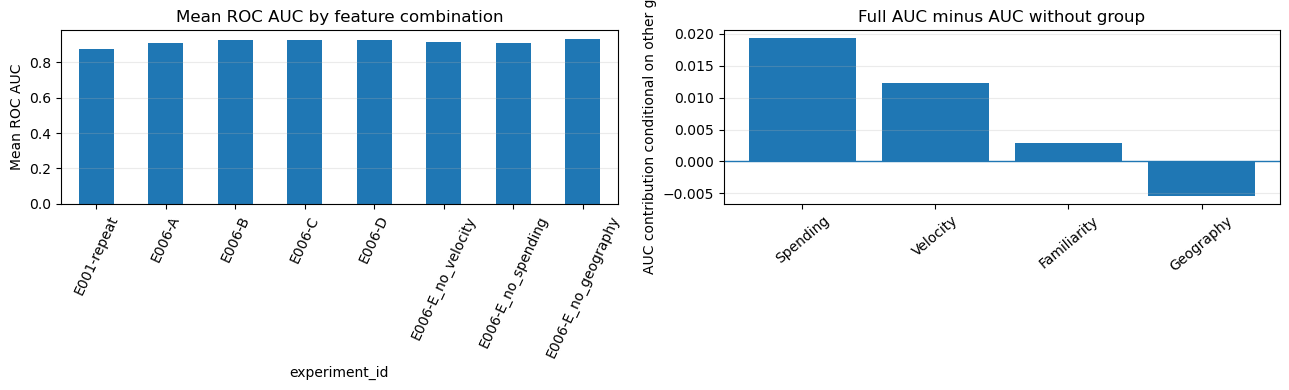

In [11]:
full_experiment = "E006-D"
drop_group_experiments = {
    "Velocity": "E006-E_no_velocity",
    "Spending": "E006-E_no_spending",
    "Geography": "E006-E_no_geography",
    "Familiarity": "E006-C",
}

ablation_rows = []
full_fold_auc = fold_auc_df[full_experiment]
for group_name, experiment_id in drop_group_experiments.items():
    fold_losses = full_fold_auc - fold_auc_df[experiment_id]
    ablation_rows.append({
        "removed_group": group_name,
        "without_group_experiment": experiment_id,
        "full_mean_auc": float(full_fold_auc.mean()),
        "without_mean_auc": float(fold_auc_df[experiment_id].mean()),
        "mean_auc_loss_when_removed": float(fold_losses.mean()),
        "fold1_loss": float(fold_losses.loc[1]),
        "fold2_loss": float(fold_losses.loc[2]),
        "fold3_loss": float(fold_losses.loc[3]),
    })

ablation_df = pd.DataFrame(ablation_rows).sort_values(
    "mean_auc_loss_when_removed", ascending=False
)
display(ablation_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
summary_df.set_index("experiment_id")["mean_roc_auc"].plot(
    kind="bar", ax=axes[0], rot=65, title="Mean ROC AUC by feature combination"
)
axes[0].set_ylabel("Mean ROC AUC")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(
    ablation_df["removed_group"], ablation_df["mean_auc_loss_when_removed"]
)
axes[1].axhline(0, linewidth=1)
axes[1].set_title("Full AUC minus AUC without group")
axes[1].set_ylabel("AUC contribution conditional on other groups")
axes[1].tick_params(axis="x", rotation=40)
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 9 — Feature importance across all folds (diagnostic, not selection rule)

CatBoost feature importance explains how each **fitted model** uses its columns. It does not mean a feature is causal or guaranteed to improve unseen-data ROC AUC. Because engineered features can be correlated, compare **group ablation results first** and use importance only for interpretation.

,feature,mean_importance,std_importance
3,amount_to_card_median,18.437525,1.094256
1,amount,12.042722,3.217356
23,merchant_id,11.702830,2.034730
19,merchant_category,10.955405,3.106024
2,amount_minus_card_median,7.543371,1.816753
24,minutes_since_previous_txn,7.214120,1.634892
7,card_merchant_txn_count,6.394914,1.488838
6,card_id,5.635493,0.450953
18,is_foreign_merchant,5.191267,1.830380
17,is_foreign_ip,1.813071,0.587321


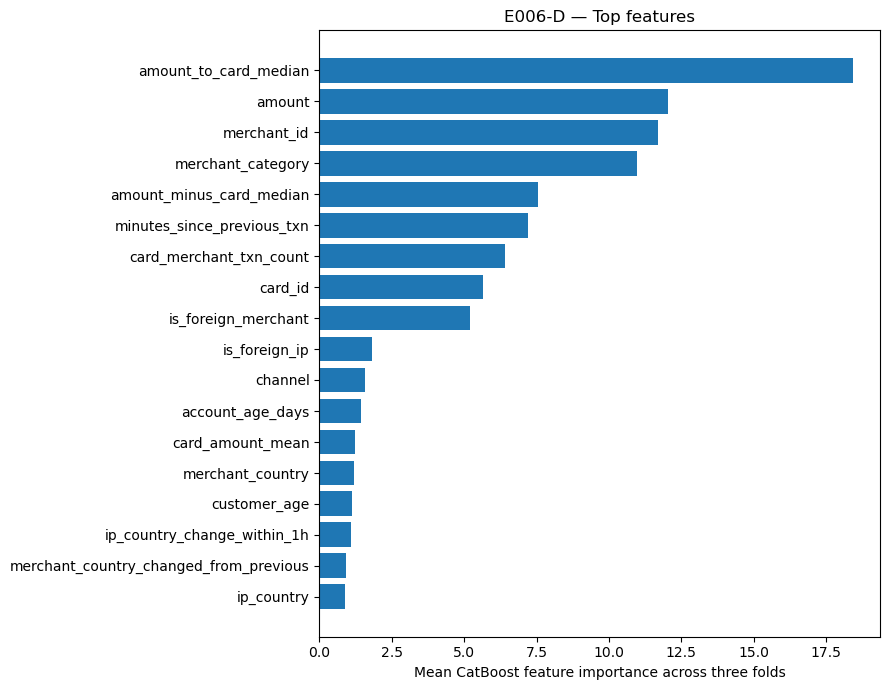

In [12]:
full_importance = importance_df.loc[
    importance_df["experiment_id"] == "E006-D"
]
importance_summary = (
    full_importance.groupby("feature", as_index=False)
    .agg(mean_importance=("importance", "mean"),
         std_importance=("importance", "std"))
    .sort_values("mean_importance", ascending=False)
)
display(importance_summary)

plt.figure(figsize=(9, 7))
top = importance_summary.head(18).iloc[::-1]
plt.barh(top["feature"], top["mean_importance"])
plt.xlabel("Mean CatBoost feature importance across three folds")
plt.title("E006-D — Top features")
plt.tight_layout()
plt.show()

## 10 — Save E006 experiment results

The CSV files are compact and suitable for Git. They save **fold-level results**, **experiment summary**, **per-fold importance**, and **the group-ablation table**. Large model binaries are not saved.

In [13]:
experiments_dir = project_root / "experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

csv_outputs = {
    "E006_cv_results.csv": results_df,
    "E006_summary.csv": summary_df,
    "E006_feature_importance.csv": importance_df,
    "E006_group_ablation.csv": ablation_df,
}
for name, table in csv_outputs.items():
    output_file = experiments_dir / name
    table.to_csv(output_file, index=False)
    print("Saved:", output_file)

Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E006_cv_results.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E006_summary.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E006_feature_importance.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E006_group_ablation.csv


## 11 — Experiment conclusion (complete **after** running)

Use this structure for a final Markdown note in your GitHub notebook:

**Objective:** Find out whether combining independently useful feature groups provides complementary fraud-discrimination information.

**Key results to fill in:**

| Experiment | Mean ROC AUC | Difference vs E006-A | Fold stability | Decision |
|:--|--:|--:|:--|:--|
| E006-A (V only) | *from output* | — | *from output* | reference |
| E006-B (V+S) | *from output* | *from output* | *from output* | evaluate |
| E006-C (V+S+G) | *from output* | *from output* | *from output* | evaluate |
| E006-D (V+S+G+F) | *from output* | *from output* | *from output* | evaluate |

**Questions to answer:**

1. Does **E006-B** improve on our previous best E003-A (approximately **0.90917**) across multiple folds?
2. Does the **full model** outperform the forward combinations?
3. Which feature group's **removal** causes the largest decline in mean ROC AUC?
4. Is the highest mean score driven entirely by one fold, or do improvements repeat?
5. Could the selected features be used in **real-time fraud detection**, or do they depend on permitted unlabeled future data?

**Decision rule:** Prefer a model with better mean AUC **and** convincing paired fold performance, not merely the most features or highest feature importance. Because we repeatedly used these validation windows for choosing features, the selected model's development AUC can be optimistic.

**Next:** E007 — Feature selection and hyperparameter optimization, with an explicit strategy for an independent final evaluation before competition submission.